# Esteira de Aprendizado de Máquina — Câncer do Colo do Útero (Cervical Cancer Risk Factors)

**Problema:** classificação binária — prever o resultado da **biópsia** (`Biopsy`: 0 = negativa, 1 = positiva) a partir de hábitos, histórico ginecológico e histórico de DSTs das pacientes.

**Fonte dos dados:** UCI Machine Learning Repository — *Cervical Cancer (Risk Factors)*, coletado no Hospital Universitário de Caracas (Venezuela). São 858 pacientes e 36 atributos.

---

### Etapas da esteira

1. Importação das bibliotecas
2. Carregamento do conjunto de dados
3. Estatísticas descritivas gerais
4. Transformações nas **colunas**
5. Transformações nas **linhas**
6. Divisão em treino, validação e teste
7. Treinamento e avaliação dos modelos
8. Matriz de confusão e acurácia no conjunto de teste
9. Implantação do modelo e predição de novos casos

> **Aviso:** trabalho com fins acadêmicos. O modelo não substitui avaliação médica.

## 1. Importação de Bibliotecas

In [ ]:
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


## 2. Carregamento do Conjunto de Dados

O arquivo `cervical_cancer_risk_factors.zip` fica na pasta `data/` do projeto. Caso o CSV ainda não tenha sido extraído, a célula abaixo faz a extração automaticamente.

Os dados originais usam o caractere `?` para indicar valores ausentes. Por isso, a leitura é feita em duas partes: primeiro o arquivo bruto (para contar os `?`) e depois a conversão para tipos numéricos.

### Dicionário de dados (resumo)

| Grupo | Atributos |
|---|---|
| Perfil | `Age`, `Number of sexual partners`, `First sexual intercourse`, `Num of pregnancies` |
| Tabagismo | `Smokes`, `Smokes (years)`, `Smokes (packs/year)` |
| Contracepção | `Hormonal Contraceptives` (+ anos), `IUD` (+ anos) |
| DSTs | `STDs`, `STDs (number)`, 12 indicadores por tipo de DST, `STDs: Number of diagnosis`, tempo desde o 1º/último diagnóstico |
| Diagnósticos prévios | `Dx:Cancer`, `Dx:CIN`, `Dx:HPV`, `Dx` |
| Exames de rastreio | `Hinselmann`, `Schiller`, `Citology` |
| **Alvo** | **`Biopsy`** (0 = negativa, 1 = positiva) |

In [4]:
DATA_DIR = Path(".")
CSV_PATH = DATA_DIR / "risk_factors_cervical_cancer.csv"
ZIP_PATH = DATA_DIR / "cervical_cancer_risk_factors.zip"

# Caso os arquivos estejam em uma pasta 'data', ajusta o caminho
if not CSV_PATH.exists():
    DATA_DIR = Path("data")
    CSV_PATH = DATA_DIR / "risk_factors_cervical_cancer.csv"
    ZIP_PATH = DATA_DIR / "cervical_cancer_risk_factors.zip"

if not CSV_PATH.exists() and ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH) as arquivo_zip:
        arquivo_zip.extractall(DATA_DIR)

df_raw = pd.read_csv(CSV_PATH)
print(f"Dimensões do arquivo bruto: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
df_raw.head(10)

Dimensões do arquivo bruto: 858 linhas x 36 colunas


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,?,?,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,?,?,0,0,0,0,0,0,0,0
2,34,1.0,?,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,?,?,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,...,?,?,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,...,?,?,0,0,0,0,0,0,0,0
5,42,3.0,23.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,?,?,0,0,0,0,0,0,0,0
6,51,3.0,17.0,6.0,1.0,34.0,3.4,0.0,0.0,1.0,...,?,?,0,0,0,0,1,1,0,1
7,26,1.0,26.0,3.0,0.0,0.0,0.0,1.0,2.0,1.0,...,?,?,0,0,0,0,0,0,0,0
8,45,1.0,20.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,...,?,?,1,0,1,1,0,0,0,0
9,44,3.0,15.0,?,1.0,1.266972909,2.8,0.0,0.0,?,...,?,?,0,0,0,0,0,0,0,0


In [5]:
# O caractere "?" representa valor ausente no arquivo original
interrogacoes = (df_raw == "?").sum()
print("Colunas com '?' no arquivo bruto:", int((interrogacoes > 0).sum()))
print("Total de células com '?':", int(interrogacoes.sum()))

# Conversão para numérico: "?" vira NaN
df = df_raw.replace("?", np.nan).apply(pd.to_numeric)
print("\nTipos de dados após a conversão:")
print(df.dtypes.value_counts().to_string())

Colunas com '?' no arquivo bruto: 26
Total de células com '?': 3622

Tipos de dados após a conversão:
float64    26
int64      10


## 3. Estatísticas Descritivas Gerais

In [6]:
print("=" * 70)
print("INFORMAÇÕES GERAIS")
print("=" * 70)
df.info()

INFORMAÇÕES GERAIS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858 entries, 0 to 857
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Age                                 858 non-null    int64  
 1   Number of sexual partners           832 non-null    float64
 2   First sexual intercourse            851 non-null    float64
 3   Num of pregnancies                  802 non-null    float64
 4   Smokes                              845 non-null    float64
 5   Smokes (years)                      845 non-null    float64
 6   Smokes (packs/year)                 845 non-null    float64
 7   Hormonal Contraceptives             750 non-null    float64
 8   Hormonal Contraceptives (years)     750 non-null    float64
 9   IUD                                 741 non-null    float64
 10  IUD (years)                         741 non-null    float64
 11  STDs                      

In [7]:
nulos = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% Nulos": (df.isna().mean() * 100).round(2),
}).sort_values("Nulos", ascending=False)

print("=" * 70)
print("VALORES AUSENTES POR COLUNA (somente colunas com ausência)")
print("=" * 70)
display(nulos[nulos["Nulos"] > 0])
print(f"\nTotal de células ausentes: {int(df.isna().sum().sum()):,} "
      f"({df.isna().sum().sum() / df.size * 100:.2f}% do conjunto)")
print(f"Linhas duplicadas: {int(df.duplicated().sum())}")

VALORES AUSENTES POR COLUNA (somente colunas com ausência)


,Nulos,% Nulos
STDs: Time since first diagnosis,787,91.72
STDs: Time since last diagnosis,787,91.72
IUD,117,13.64
IUD (years),117,13.64
Hormonal Contraceptives,108,12.59
Hormonal Contraceptives (years),108,12.59
STDs:HPV,105,12.24
STDs:AIDS,105,12.24
STDs:Hepatitis B,105,12.24
STDs:HIV,105,12.24



Total de células ausentes: 3,622 (11.73% do conjunto)
Linhas duplicadas: 23


In [8]:
print("=" * 70)
print("ESTATÍSTICAS DESCRITIVAS — TODAS AS VARIÁVEIS")
print("=" * 70)
desc = df.describe().T
desc["assimetria"] = df.skew()
desc["mediana"] = df.median()
display(desc[["count", "mean", "std", "min", "25%", "mediana", "75%", "max", "assimetria"]].round(3))

ESTATÍSTICAS DESCRITIVAS — TODAS AS VARIÁVEIS


,count,mean,std,min,25%,mediana,75%,max,assimetria
Age,858.0,26.821,8.498,13.0,20.0,25.0,32.0,84.0,1.394
Number of sexual partners,832.0,2.528,1.668,1.0,2.0,2.0,3.0,28.0,5.455
First sexual intercourse,851.0,16.995,2.803,10.0,15.0,17.0,18.0,32.0,1.564
Num of pregnancies,802.0,2.276,1.447,0.0,1.0,2.0,3.0,11.0,1.424
Smokes,845.0,0.146,0.353,0.0,0.0,0.0,0.0,1.0,2.014
Smokes (years),845.0,1.220,4.089,0.0,0.0,0.0,0.0,37.0,4.465
Smokes (packs/year),845.0,0.453,2.227,0.0,0.0,0.0,0.0,37.0,9.309
Hormonal Contraceptives,750.0,0.641,0.480,0.0,0.0,1.0,1.0,1.0,-0.591
Hormonal Contraceptives (years),750.0,2.256,3.764,0.0,0.0,0.5,3.0,30.0,2.626
IUD,741.0,0.112,0.316,0.0,0.0,0.0,0.0,1.0,2.465


In [9]:
ALVO = "Biopsy"

contagem = df[ALVO].value_counts().sort_index()
resumo_alvo = pd.DataFrame({
    "Contagem": contagem,
    "Percentual (%)": (contagem / len(df) * 100).round(2),
})
resumo_alvo.index = ["0 - Biópsia negativa", "1 - Biópsia positiva"]
print("=" * 70)
print("DISTRIBUIÇÃO DA VARIÁVEL ALVO (Biopsy)")
print("=" * 70)
display(resumo_alvo)
print("\nO conjunto é fortemente desbalanceado: a classe positiva é minoritária.")
print("Isso influencia a escolha das métricas e das técnicas de treinamento.")

DISTRIBUIÇÃO DA VARIÁVEL ALVO (Biopsy)


,Contagem,Percentual (%)
0 - Biópsia negativa,803,93.59
1 - Biópsia positiva,55,6.41



O conjunto é fortemente desbalanceado: a classe positiva é minoritária.
Isso influencia a escolha das métricas e das técnicas de treinamento.


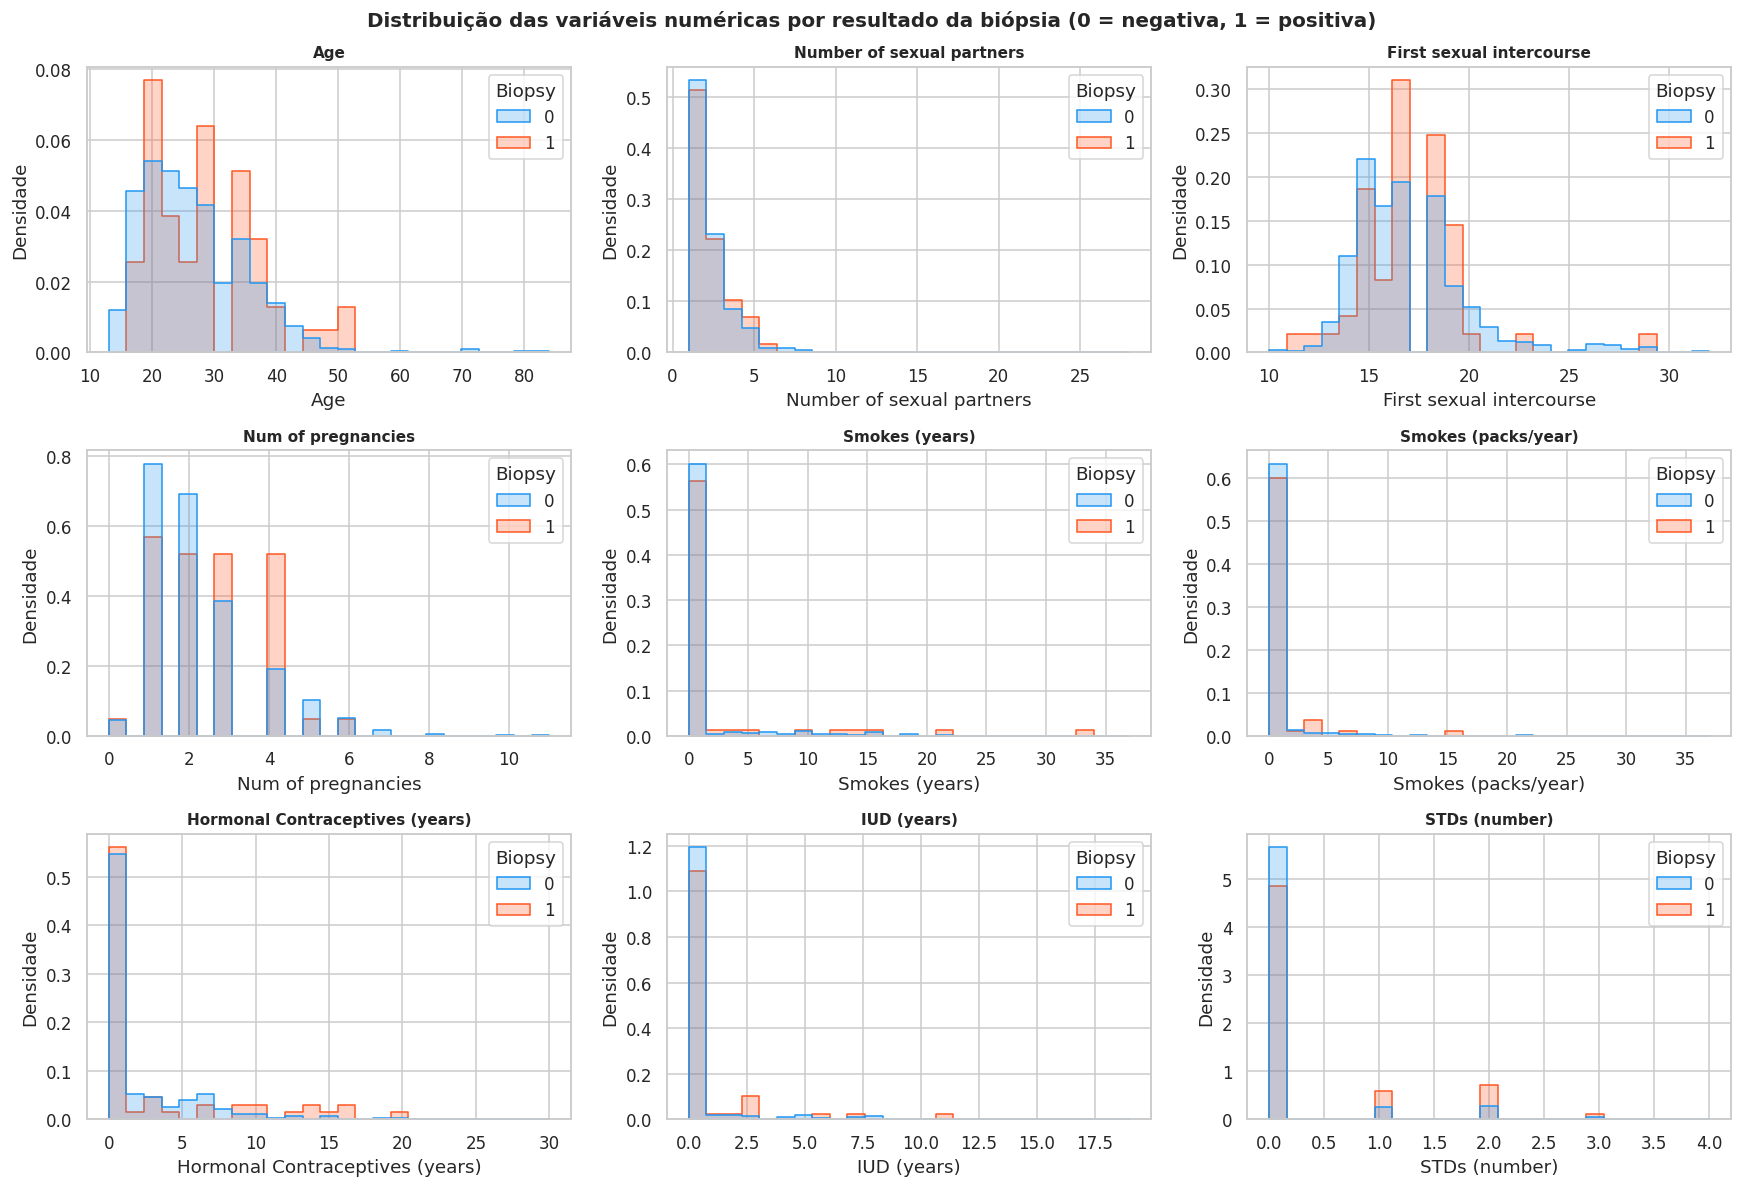

In [10]:
colunas_continuas = [
    "Age", "Number of sexual partners", "First sexual intercourse",
    "Num of pregnancies", "Smokes (years)", "Smokes (packs/year)",
    "Hormonal Contraceptives (years)", "IUD (years)", "STDs (number)",
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flatten(), colunas_continuas):
    sns.histplot(data=df, x=col, hue=ALVO, bins=25, stat="density",
                 common_norm=False, element="step", ax=ax, palette={0: "#2196F3", 1: "#FF5722"})
    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_ylabel("Densidade")
fig.suptitle("Distribuição das variáveis numéricas por resultado da biópsia (0 = negativa, 1 = positiva)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

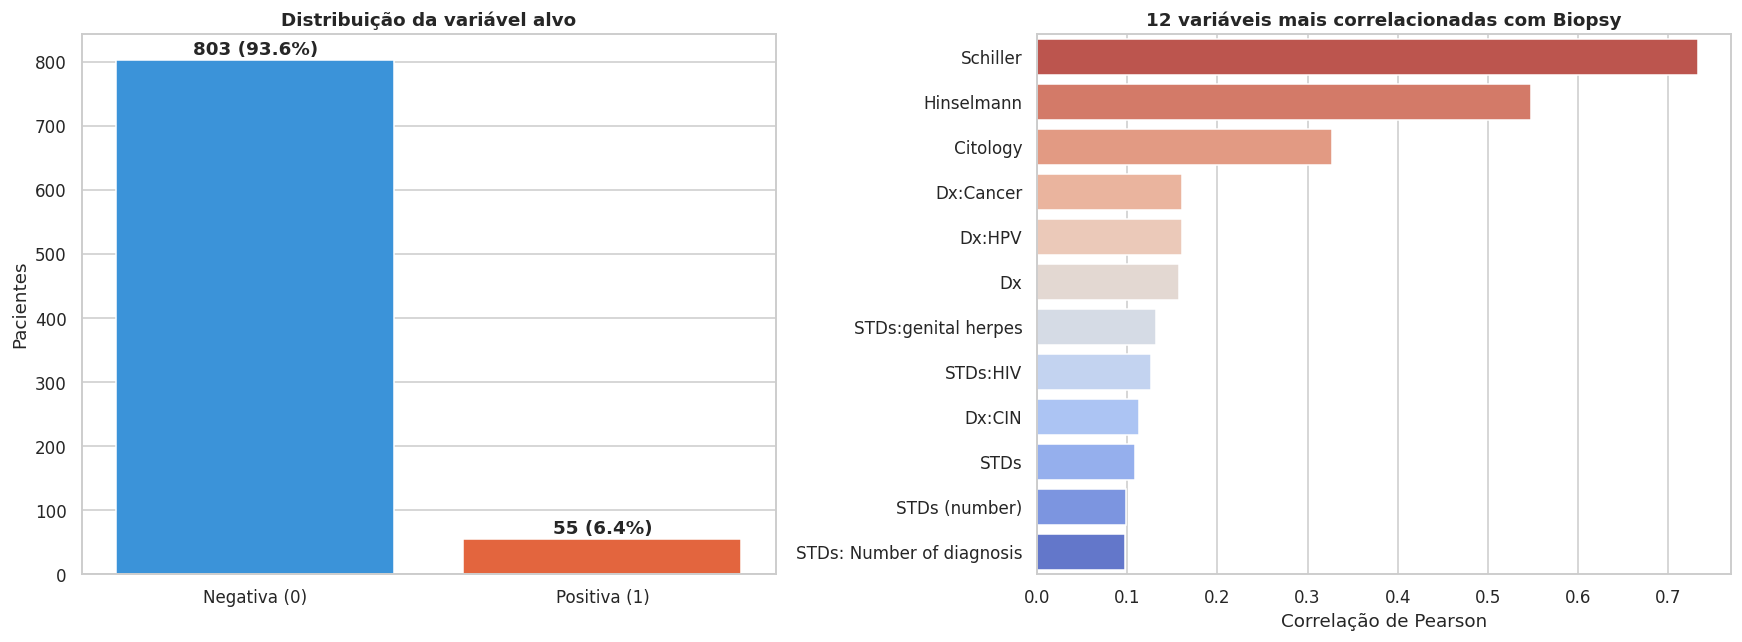

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Balanceamento do alvo
sns.barplot(x=["Negativa (0)", "Positiva (1)"], y=contagem.values,
            palette=["#2196F3", "#FF5722"], ax=axes[0])
for i, v in enumerate(contagem.values):
    axes[0].text(i, v + 8, f"{v} ({v / len(df) * 100:.1f}%)", ha="center", fontweight="bold")
axes[0].set_title("Distribuição da variável alvo", fontweight="bold")
axes[0].set_ylabel("Pacientes")

# Correlação de cada variável com o alvo
corr_alvo = (df.drop(columns=[ALVO]).corrwith(df[ALVO]).dropna()
               .sort_values(key=np.abs, ascending=False).head(12))
sns.barplot(x=corr_alvo.values, y=corr_alvo.index, palette="coolwarm_r", ax=axes[1])
axes[1].set_title("12 variáveis mais correlacionadas com Biopsy", fontweight="bold")
axes[1].set_xlabel("Correlação de Pearson")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 4. Transformações nas Colunas

Transformações aplicadas:

| # | Transformação | Motivo |
|---|---|---|
| a | Remover colunas com mais de 80% de valores ausentes | Imputar quase toda a coluna criaria informação inventada. |
| b | Remover colunas constantes | Só possuem um valor e não ajudam o modelo. |
| c | Criar a variável `Years since first intercourse` (`Age - First sexual intercourse`) | Representa o tempo de exposição, que costuma ser mais informativo que as duas variáveis isoladas. |
| d | Aplicar `log1p` nas variáveis contínuas muito assimétricas (assimetria > 1) | Reduz a influência de valores extremos e aproxima a distribuição de uma normal. |

**Sobre os exames `Hinselmann`, `Schiller` e `Citology`:** são exames de rastreio (colposcopia e citologia) realizados antes de a biópsia ser indicada, portanto estão disponíveis no momento da predição e são mantidos como variáveis de entrada. A seção 7 traz um experimento mostrando o quanto o modelo depende deles.

In [12]:
df_proc = df.copy()

# (a) Colunas com mais de 80% de ausentes
perc_nulos = df_proc.isna().mean()
cols_muitos_nulos = perc_nulos[perc_nulos > 0.80].index.tolist()
df_proc = df_proc.drop(columns=cols_muitos_nulos)
print(f"(a) Colunas removidas (> 80% de ausentes): {cols_muitos_nulos}")

# (b) Colunas constantes
cols_constantes = [c for c in df_proc.columns if df_proc[c].nunique(dropna=True) <= 1]
df_proc = df_proc.drop(columns=cols_constantes)
print(f"(b) Colunas removidas (constantes): {cols_constantes}")

print(f"\nColunas restantes: {df_proc.shape[1]} (incluindo o alvo)")

(a) Colunas removidas (> 80% de ausentes): ['STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']
(b) Colunas removidas (constantes): ['STDs:cervical condylomatosis', 'STDs:AIDS']

Colunas restantes: 32 (incluindo o alvo)


In [13]:
# (d) Seleção das colunas contínuas assimétricas
candidatas_log = [c for c in colunas_continuas if c in df_proc.columns]
assimetria_antes = df_proc[candidatas_log].skew()
COLS_LOG = assimetria_antes[assimetria_antes > 1].index.tolist()
print("Colunas que receberão log1p (assimetria > 1):")
print(assimetria_antes[COLS_LOG].round(2).to_string())


def transformar_colunas(dados, cols_log=COLS_LOG):
    # Aplica as transformações (c) e (d). Reutilizada na predição de novos casos.
    d = dados.copy()
    # (c) Tempo desde a primeira relação sexual
    d["Years since first intercourse"] = (d["Age"] - d["First sexual intercourse"]).clip(lower=0)
    # (d) log1p nas colunas assimétricas (as originais são substituídas)
    for c in cols_log:
        d[f"{c} (log)"] = np.log1p(d[c])
    return d.drop(columns=cols_log)


df_proc_antes = df_proc.copy()
df_proc = transformar_colunas(df_proc)

assimetria_depois = df_proc[[f"{c} (log)" for c in COLS_LOG]].skew()
comparacao = pd.DataFrame({
    "Assimetria antes": assimetria_antes[COLS_LOG].values,
    "Assimetria depois (log1p)": assimetria_depois.values,
}, index=COLS_LOG).round(2)
print("\nEfeito da transformação logarítmica:")
display(comparacao)
print(f"\nShape após as transformações de coluna: {df_proc.shape}")

Colunas que receberão log1p (assimetria > 1):
Age                                1.39
Number of sexual partners          5.45
First sexual intercourse           1.56
Num of pregnancies                 1.42
Smokes (years)                     4.47
Smokes (packs/year)                9.31
Hormonal Contraceptives (years)    2.63
IUD (years)                        5.00
STDs (number)                      3.40

Efeito da transformação logarítmica:


,Assimetria antes,Assimetria depois (log1p)
Age,1.39,0.30
Number of sexual partners,5.45,0.55
First sexual intercourse,1.56,0.82
Num of pregnancies,1.42,0.16
Smokes (years),4.47,2.67
Smokes (packs/year),9.31,3.88
Hormonal Contraceptives (years),2.63,0.90
IUD (years),5.00,3.25
STDs (number),3.40,2.92



Shape após as transformações de coluna: (858, 33)


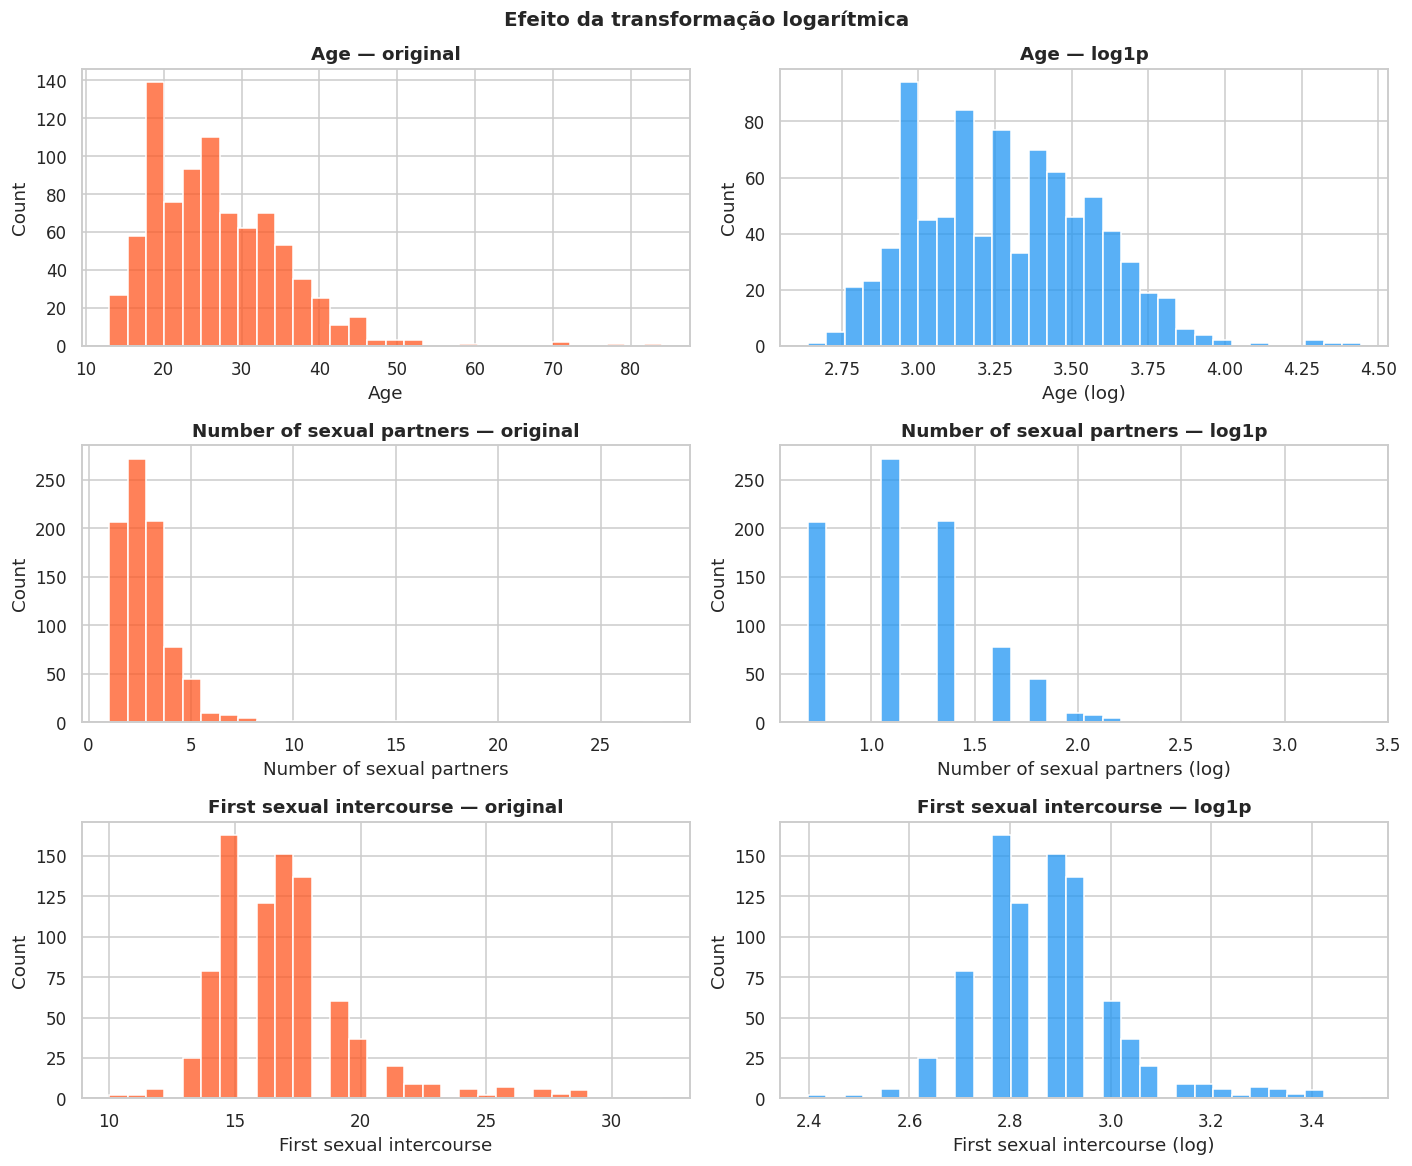

In [14]:
mostrar = COLS_LOG[:3]
fig, axes = plt.subplots(len(mostrar), 2, figsize=(13, 3.6 * len(mostrar)))
for i, col in enumerate(mostrar):
    sns.histplot(df_proc_antes[col].dropna(), bins=30, color="#FF5722", ax=axes[i][0])
    axes[i][0].set_title(f"{col} — original", fontweight="bold")
    sns.histplot(df_proc[f"{col} (log)"].dropna(), bins=30, color="#2196F3", ax=axes[i][1])
    axes[i][1].set_title(f"{col} — log1p", fontweight="bold")
fig.suptitle("Efeito da transformação logarítmica", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Transformações nas Linhas

| # | Transformação | Motivo |
|---|---|---|
| a | Remover linhas duplicadas | Registros repetidos poderiam cair ao mesmo tempo em treino e teste, o que causaria vazamento de dados. |
| b | Remover linhas com mais de 30% das variáveis de entrada ausentes | São pacientes que praticamente não responderam ao questionário (histórico de DSTs, contracepção etc.). Preencher todos esses valores seria inventar a maior parte do registro. |

O preenchimento dos valores ausentes **restantes** (mediana) é feito depois da divisão dos dados, dentro do pipeline, usando somente estatísticas do conjunto de treino.

In [15]:
n_inicial = len(df_proc)
positivos_inicial = int(df_proc[ALVO].sum())

# (a) Duplicadas
df_proc = df_proc.drop_duplicates()
n_pos_duplicadas = len(df_proc)
print(f"(a) Linhas duplicadas removidas: {n_inicial - n_pos_duplicadas}")

# (b) Linhas quase vazias
colunas_entrada = [c for c in df_proc.columns if c != ALVO]
prop_nulos_linha = df_proc[colunas_entrada].isna().mean(axis=1)
print("\nDistribuição da proporção de ausentes por linha:")
print(prop_nulos_linha.describe().round(3).to_string())

LIMITE_NULOS_LINHA = 0.30
df_clean = df_proc[prop_nulos_linha <= LIMITE_NULOS_LINHA].copy()   # o índice original é mantido
print(f"\n(b) Linhas removidas (> {LIMITE_NULOS_LINHA:.0%} de ausentes): {n_pos_duplicadas - len(df_clean)}")

print("\n" + "-" * 50)
print(f"Linhas antes   : {n_inicial}  (positivos: {positivos_inicial})")
print(f"Linhas depois  : {len(df_clean)}  (positivos: {int(df_clean[ALVO].sum())})")
print(f"Linhas removidas no total: {n_inicial - len(df_clean)} ({(n_inicial - len(df_clean)) / n_inicial:.1%})")
print(f"Ausentes restantes nas variáveis de entrada: {int(df_clean[colunas_entrada].isna().sum().sum())}")

(a) Linhas duplicadas removidas: 23

Distribuição da proporção de ausentes por linha:
count    835.000
mean       0.066
std        0.162
min        0.000
25%        0.000
50%        0.000
75%        0.000
max        0.594

(b) Linhas removidas (> 30% de ausentes): 100

--------------------------------------------------
Linhas antes   : 858  (positivos: 55)
Linhas depois  : 735  (positivos: 52)
Linhas removidas no total: 123 (14.3%)
Ausentes restantes nas variáveis de entrada: 161


## 6. Divisão em Subconjuntos: Treino / Validação / Teste

| Subconjunto | Proporção | Uso |
|---|---|---|
| **Treino** | 60% | Ajuste dos modelos |
| **Validação** | 20% | Comparação entre modelos e escolha do limiar de decisão |
| **Teste** | 20% | Avaliação final, usado uma única vez |

A divisão é **estratificada** pelo alvo, para que a proporção de casos positivos seja a mesma nos três subconjuntos.

In [18]:
FEATURES = [c for c in df_clean.columns if c != ALVO]
X = df_clean[FEATURES]
y = df_clean[ALVO]

# 1º corte: separa 20% para teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# 2º corte: dos 80% restantes, 25% viram validação (0,25 x 0,80 = 20% do total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)

print(f"Variáveis de entrada: {len(FEATURES)}")
print(f"\n{'Subconjunto':<12} {'Amostras':>9} {'% do total':>11} {'Positivos':>10} {'% positivos':>12}")
print("-" * 58)
for nome, ys in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:<12} {len(ys):>9} {len(ys) / len(y) * 100:>10.1f}% {int(ys.sum()):>10} {ys.mean() * 100:>11.2f}%")

Variáveis de entrada: 32

Subconjunto   Amostras  % do total  Positivos  % positivos
----------------------------------------------------------
Treino             441       60.0%         32        7.26%
Validação          147       20.0%         10        6.80%
Teste              147       20.0%         10        6.80%


## 7. Treinamento e Avaliação dos Modelos

Como a classe positiva é rara (~7%), um modelo que sempre responde "negativo" já teria acurácia próxima de 93%. Por isso, além da acurácia, a comparação usa **precisão média** (área sob a curva Precisão-Recall), **ROC AUC**, **recall** e **F1**.

Cada candidato é um `Pipeline` com:
1. `SimpleImputer(median)` — preenche ausentes com a mediana **do treino**;
2. `StandardScaler` — padroniza as variáveis (também ajustado só no treino);
3. o classificador, com `class_weight="balanced"` para compensar o desbalanceamento.

Os candidatos são treinados com o conjunto de **treino** e comparados no conjunto de **validação**. O de maior precisão média na validação é o escolhido.

In [19]:
def montar_pipeline(classificador):
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("padronizador", StandardScaler()),
        ("modelo", classificador),
    ])


candidatos = {
    "Regressão Logística": LogisticRegression(
        C=0.1, class_weight="balanced", max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_depth=2, learning_rate=0.03, max_iter=100, min_samples_leaf=20,
        class_weight="balanced", random_state=SEED),
}

pipelines = {}
linhas = []
for nome, clf in candidatos.items():
    pipe = montar_pipeline(clf).fit(X_train, y_train)
    pipelines[nome] = pipe
    prob_val = pipe.predict_proba(X_val)[:, 1]
    pred_val = (prob_val >= 0.5).astype(int)
    linhas.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_val, pred_val),
        "Recall": recall_score(y_val, pred_val),
        "Precisão": precision_score(y_val, pred_val, zero_division=0),
        "F1": f1_score(y_val, pred_val, zero_division=0),
        "ROC AUC": roc_auc_score(y_val, prob_val),
        "Precisão média": average_precision_score(y_val, prob_val),
    })

tabela_val = pd.DataFrame(linhas).set_index("Modelo").sort_values("Precisão média", ascending=False)
print("Desempenho dos candidatos no conjunto de VALIDAÇÃO (limiar = 0,5):")
display(tabela_val.round(4))

NOME_MELHOR = tabela_val.index[0]
print(f"\nModelo escolhido: {NOME_MELHOR}")

Desempenho dos candidatos no conjunto de VALIDAÇÃO (limiar = 0,5):


,Acurácia,Recall,Precisão,F1,ROC AUC,Precisão média
Modelo,,,,,,
Extra Trees,0.9320,0.8,0.5000,0.6154,0.9051,0.6251
Regressão Logística,0.9184,0.9,0.4500,0.6000,0.8818,0.6152
Random Forest,0.9388,0.8,0.5333,0.6400,0.9358,0.6007
Gradient Boosting,0.9388,0.8,0.5333,0.6400,0.8814,0.4487



Modelo escolhido: Extra Trees


In [20]:
# Estabilidade do modelo escolhido: validação cruzada estratificada apenas no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scores_cv = cross_val_score(montar_pipeline(candidatos[NOME_MELHOR]), X_train, y_train,
                            cv=cv, scoring="average_precision")
print(f"Precisão média em 5 folds (treino): {scores_cv.mean():.4f} +/- {scores_cv.std():.4f}")
print("Por fold:", np.round(scores_cv, 4))

Precisão média em 5 folds (treino): 0.7360 +/- 0.1845
Por fold: [0.8598 0.4333 0.6173 0.8357 0.9341]


Modelo: Extra Trees | limiar = 0.50

Acurácia na validação: 0.9320 (93.20%)

Relatório de classificação — validação:
                      precision    recall  f1-score   support

Biópsia negativa (0)       0.98      0.94      0.96       137
Biópsia positiva (1)       0.50      0.80      0.62        10

            accuracy                           0.93       147
           macro avg       0.74      0.87      0.79       147
        weighted avg       0.95      0.93      0.94       147



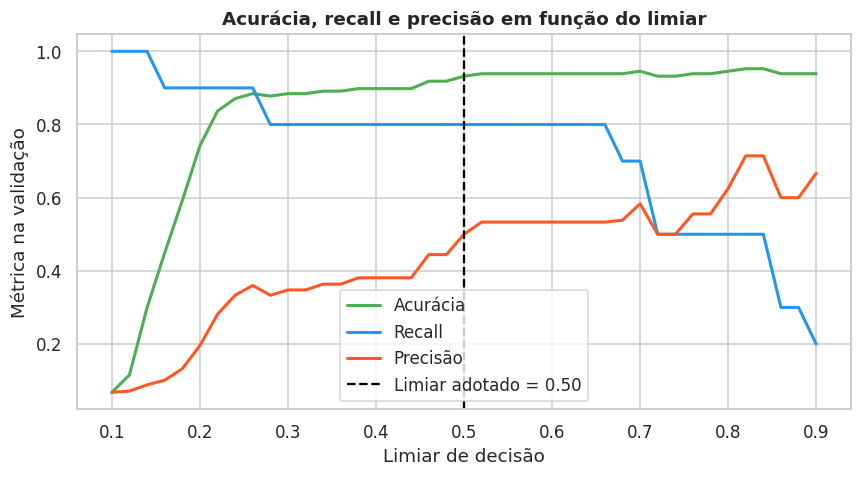

In [21]:
# Limiar de decisão: o padrão de 0,50. Com apenas 10 casos positivos na validação,
# ajustar o limiar nesse conjunto levaria a um valor sensível ao acaso. A varredura abaixo
# serve para verificar se 0,50 é um ponto de equilíbrio razoável entre recall e precisão.
modelo_final = pipelines[NOME_MELHOR]
LIMIAR = 0.50

prob_val = modelo_final.predict_proba(X_val)[:, 1]
pred_val = (prob_val >= LIMIAR).astype(int)
acc_val = accuracy_score(y_val, pred_val)
print(f"Modelo: {NOME_MELHOR} | limiar = {LIMIAR:.2f}")
print(f"\nAcurácia na validação: {acc_val:.4f} ({acc_val * 100:.2f}%)")
print("\nRelatório de classificação — validação:")
print(classification_report(y_val, pred_val, target_names=["Biópsia negativa (0)", "Biópsia positiva (1)"], zero_division=0))

grade = np.arange(0.10, 0.91, 0.02)
varredura = pd.DataFrame({
    "Acurácia": [accuracy_score(y_val, (prob_val >= t).astype(int)) for t in grade],
    "Recall": [recall_score(y_val, (prob_val >= t).astype(int)) for t in grade],
    "Precisão": [precision_score(y_val, (prob_val >= t).astype(int), zero_division=0) for t in grade],
}, index=grade)

plt.figure(figsize=(8, 4.5))
for col, cor in zip(varredura.columns, ["#4CAF50", "#2196F3", "#FF5722"]):
    plt.plot(varredura.index, varredura[col], lw=2, label=col, color=cor)
plt.axvline(LIMIAR, color="black", ls="--", label=f"Limiar adotado = {LIMIAR:.2f}")
plt.xlabel("Limiar de decisão")
plt.ylabel("Métrica na validação")
plt.title("Acurácia, recall e precisão em função do limiar", fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# Experimento: o quanto o modelo depende dos exames de rastreio?
# Validação cruzada repetida em treino + validação (o teste continua intocado).
EXAMES = ["Hinselmann", "Schiller", "Citology"]
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

linhas_abl = []
for rotulo, cols in [("Com os exames de rastreio", FEATURES),
                     ("Somente fatores de risco (sem os exames)", [c for c in FEATURES if c not in EXAMES])]:
    r = cross_validate(montar_pipeline(candidatos[NOME_MELHOR]), X_temp[cols], y_temp,
                       cv=cv_rep, scoring=["roc_auc", "average_precision"], n_jobs=-1)
    linhas_abl.append({
        "Conjunto de variáveis": rotulo,
        "Nº de variáveis": len(cols),
        "ROC AUC (média)": r["test_roc_auc"].mean(),
        "Precisão média (média)": r["test_average_precision"].mean(),
    })

abl = pd.DataFrame(linhas_abl).set_index("Conjunto de variáveis")
display(abl.round(3))
print("Sem os exames de rastreio, o desempenho cai muito: os fatores de risco isolados")
print("carregam pouca informação sobre o resultado da biópsia nesta base.")

,Nº de variáveis,ROC AUC (média),Precisão média (média)
Conjunto de variáveis,,,
Com os exames de rastreio,32,0.944,0.710
Somente fatores de risco (sem os exames),29,0.613,0.165


Sem os exames de rastreio, o desempenho cai muito: os fatores de risco isolados
carregam pouca informação sobre o resultado da biópsia nesta base.


## 8. Matriz de Confusão e Acurácia (Conjunto de Teste)

O conjunto de teste não foi usado em nenhuma decisão anterior (nem para escolher o modelo, nem o limiar, nem as transformações). Os resultados abaixo, portanto, são uma estimativa honesta do desempenho em dados novos.

In [23]:
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= LIMIAR).astype(int)

acuracia_teste = accuracy_score(y_test, pred_test)
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()
acuracia_baseline = 1 - y_test.mean()

print("=" * 66)
print(f"RESULTADOS FINAIS — CONJUNTO DE TESTE  ({NOME_MELHOR}, limiar = {LIMIAR:.2f})")
print("=" * 66)
print(f"\nAcurácia                 : {acuracia_teste:.4f}  ({acuracia_teste * 100:.2f}%)")
print(f"Acurácia de referência   : {acuracia_baseline:.4f}  (modelo que sempre responde 'negativa')")
print(f"Recall (sensibilidade)   : {recall_score(y_test, pred_test):.4f}")
print(f"Especificidade           : {tn / (tn + fp):.4f}")
print(f"Precisão                 : {precision_score(y_test, pred_test, zero_division=0):.4f}")
print(f"F1                       : {f1_score(y_test, pred_test, zero_division=0):.4f}")
print(f"ROC AUC                  : {roc_auc_score(y_test, prob_test):.4f}")
print(f"Precisão média (PR AUC)  : {average_precision_score(y_test, prob_test):.4f}")
print(f"\nVerdadeiros negativos: {tn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdadeiros positivos: {tp}")
print("\nRelatório de classificação:")
print(classification_report(y_test, pred_test, target_names=["Biópsia negativa (0)", "Biópsia positiva (1)"], zero_division=0))

RESULTADOS FINAIS — CONJUNTO DE TESTE  (Extra Trees, limiar = 0.50)

Acurácia                 : 0.9592  (95.92%)
Acurácia de referência   : 0.9320  (modelo que sempre responde 'negativa')
Recall (sensibilidade)   : 0.9000
Especificidade           : 0.9635
Precisão                 : 0.6429
F1                       : 0.7500
ROC AUC                  : 0.9182
Precisão média (PR AUC)  : 0.7479

Verdadeiros negativos: 132 | Falsos positivos: 5 | Falsos negativos: 1 | Verdadeiros positivos: 9

Relatório de classificação:
                      precision    recall  f1-score   support

Biópsia negativa (0)       0.99      0.96      0.98       137
Biópsia positiva (1)       0.64      0.90      0.75        10

            accuracy                           0.96       147
           macro avg       0.82      0.93      0.86       147
        weighted avg       0.97      0.96      0.96       147



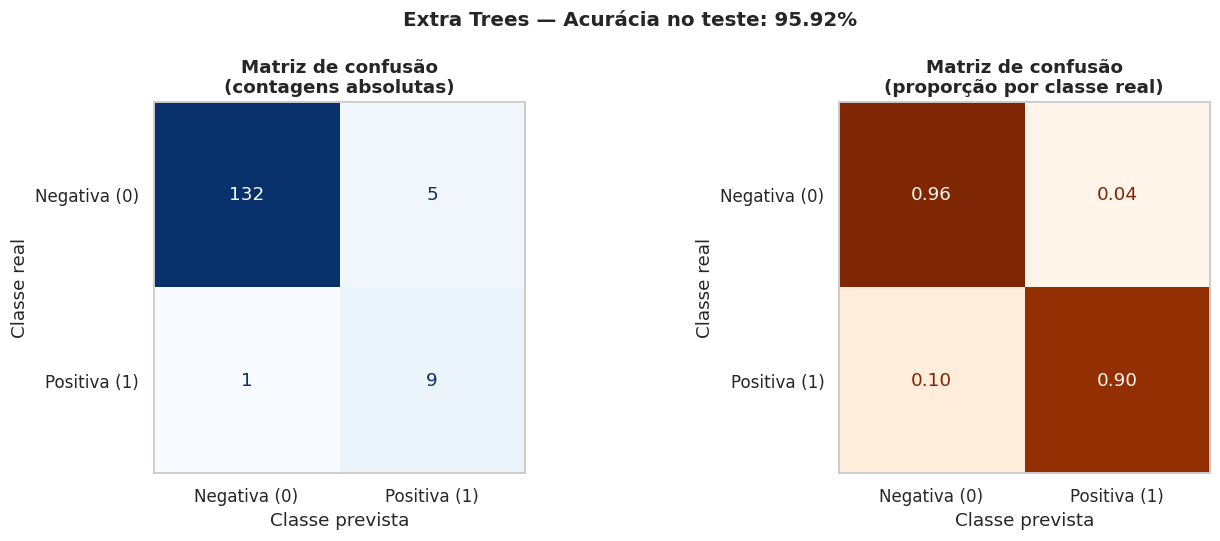

In [24]:
rotulos = ["Negativa (0)", "Positiva (1)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusão\n(contagens absolutas)", fontweight="bold")
axes[0].set_xlabel("Classe prevista")
axes[0].set_ylabel("Classe real")
axes[0].grid(False)

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm, display_labels=rotulos).plot(
    ax=axes[1], cmap="Oranges", colorbar=False, values_format=".2f")
axes[1].set_title("Matriz de confusão\n(proporção por classe real)", fontweight="bold")
axes[1].set_xlabel("Classe prevista")
axes[1].set_ylabel("Classe real")
axes[1].grid(False)

fig.suptitle(f"{NOME_MELHOR} — Acurácia no teste: {acuracia_teste * 100:.2f}%", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

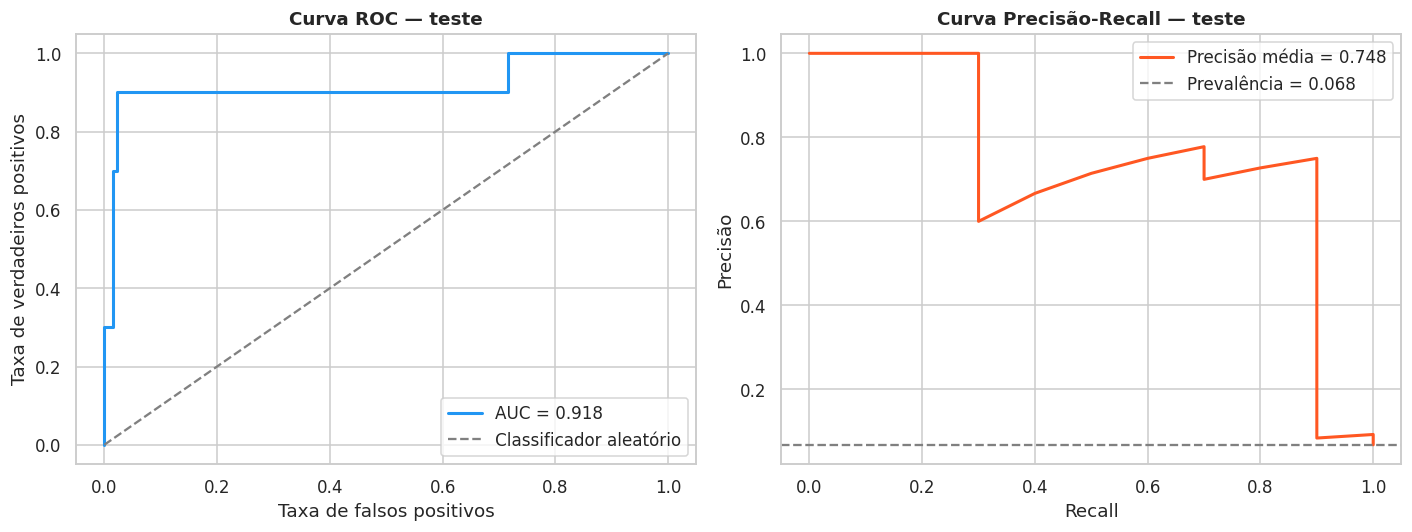

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

fpr, tpr, _ = roc_curve(y_test, prob_test)
axes[0].plot(fpr, tpr, color="#2196F3", lw=2, label=f"AUC = {roc_auc_score(y_test, prob_test):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Classificador aleatório")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].set_title("Curva ROC — teste", fontweight="bold")
axes[0].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_test, prob_test)
axes[1].plot(rec, prec, color="#FF5722", lw=2,
             label=f"Precisão média = {average_precision_score(y_test, prob_test):.3f}")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"Prevalência = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precisão-Recall — teste", fontweight="bold")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

In [ ]:
# Importância das variáveis (por permutação, calculada na validação)
imp = permutation_importance(modelo_final, X_val, y_val, scoring="average_precision",
                             n_repeats=30, random_state=SEED, n_jobs=-1)
serie_imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=serie_imp.values, y=serie_imp.index, palette="Blues_r")
plt.title("10 variáveis mais importantes (importância por permutação)", fontweight="bold")
plt.xlabel("Queda média na precisão média ao embaralhar a variável")
plt.tight_layout()
plt.show()

## 9. Implantação do Modelo e Predição

Para simular a implantação, o modelo treinado (pipeline completo, limiar e lista de variáveis) é salvo em disco com `joblib`, carregado novamente como se fosse outro sistema e usado para classificar novas pacientes.

A função `prever_paciente` recebe os dados **brutos** da paciente (como no questionário original), aplica as mesmas transformações de coluna usadas no treino e devolve a probabilidade e a classe prevista.

In [26]:
Path("modelo").mkdir(exist_ok=True)

COLUNAS_BRUTAS = [c for c in df.columns if c != ALVO]

artefato = {
    "pipeline": modelo_final,
    "limiar": LIMIAR,
    "features": FEATURES,
    "cols_log": COLS_LOG,
    "colunas_brutas": COLUNAS_BRUTAS,
    "nome_modelo": NOME_MELHOR,
}
joblib.dump(artefato, "modelo/modelo_cervical.joblib")
print("Modelo salvo em: modelo/modelo_cervical.joblib")

# Carregamento, como seria feito em outro sistema
modelo_implantado = joblib.load("modelo/modelo_cervical.joblib")
print(f"Modelo carregado: {modelo_implantado['nome_modelo']} | limiar = {modelo_implantado['limiar']:.2f}")


def prever_paciente(dados, artefato=modelo_implantado):
    # Recebe um dicionário com os dados brutos de uma paciente e devolve a predição
    novo = pd.DataFrame([dados]).reindex(columns=artefato["colunas_brutas"])
    novo = transformar_colunas(novo, artefato["cols_log"])[artefato["features"]]
    prob = artefato["pipeline"].predict_proba(novo)[0, 1]
    classe = int(prob >= artefato["limiar"])
    return {"probabilidade_biopsia_positiva": round(float(prob), 4), "classe_prevista": classe}

Modelo salvo em: modelo/modelo_cervical.joblib
Modelo carregado: Extra Trees | limiar = 0.50


In [27]:
# Pacientes fictícias para demonstração (campos não informados são tratados como ausentes)
paciente_baixo_risco = {
    "Age": 24, "Number of sexual partners": 1, "First sexual intercourse": 19, "Num of pregnancies": 0,
    "Smokes": 0, "Smokes (years)": 0, "Smokes (packs/year)": 0,
    "Hormonal Contraceptives": 0, "Hormonal Contraceptives (years)": 0, "IUD": 0, "IUD (years)": 0,
    "STDs": 0, "STDs (number)": 0, "STDs: Number of diagnosis": 0,
    "Dx:Cancer": 0, "Dx:CIN": 0, "Dx:HPV": 0, "Dx": 0,
    "Hinselmann": 0, "Schiller": 0, "Citology": 0,
}
paciente_alto_risco = {
    "Age": 41, "Number of sexual partners": 6, "First sexual intercourse": 14, "Num of pregnancies": 4,
    "Smokes": 1, "Smokes (years)": 20, "Smokes (packs/year)": 9,
    "Hormonal Contraceptives": 1, "Hormonal Contraceptives (years)": 12, "IUD": 1, "IUD (years)": 6,
    "STDs": 1, "STDs (number)": 2, "STDs:condylomatosis": 1, "STDs:vulvo-perineal condylomatosis": 1,
    "STDs:HPV": 1, "STDs: Number of diagnosis": 1,
    "Dx:Cancer": 0, "Dx:CIN": 1, "Dx:HPV": 1, "Dx": 1,
    "Hinselmann": 0, "Schiller": 1, "Citology": 0,
}

# Um caso real do conjunto de teste (com o resultado conhecido), para conferir a predição
idx_real = y_test[y_test == 1].index[0]
paciente_real = df.loc[idx_real, COLUNAS_BRUTAS].to_dict()

casos = {
    "Paciente A (perfil de baixo risco)": (paciente_baixo_risco, None),
    "Paciente B (perfil de alto risco)": (paciente_alto_risco, None),
    f"Paciente C (registro do teste, índice {idx_real})": (paciente_real, int(y_test.loc[idx_real])),
}

resultados = []
for nome, (dados, real) in casos.items():
    r = prever_paciente(dados)
    resultados.append({
        "Paciente": nome,
        "P(biópsia positiva)": r["probabilidade_biopsia_positiva"],
        "Predição": "POSITIVA (1)" if r["classe_prevista"] == 1 else "NEGATIVA (0)",
        "Resultado real": "-" if real is None else ("POSITIVA (1)" if real == 1 else "NEGATIVA (0)"),
    })

print(f"Limiar de decisão: {modelo_implantado['limiar']:.2f}\n")
display(pd.DataFrame(resultados).set_index("Paciente"))

Limiar de decisão: 0.50



,P(biópsia positiva),Predição,Resultado real
Paciente,,,
Paciente A (perfil de baixo risco),0.1182,NEGATIVA (0),-
Paciente B (perfil de alto risco),0.6842,POSITIVA (1),-
"Paciente C (registro do teste, índice 496)",0.8694,POSITIVA (1),POSITIVA (1)


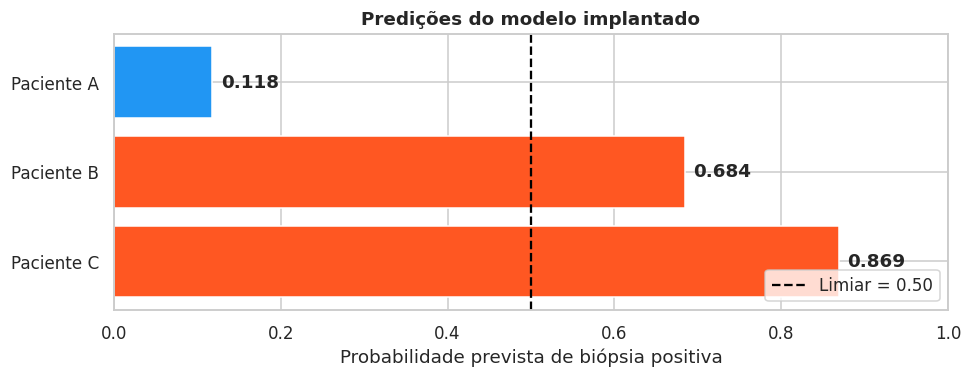

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.6))
rotulos_pac = ["Paciente A", "Paciente B", "Paciente C"]
probs = [r["P(biópsia positiva)"] for r in resultados]
cores = ["#FF5722" if p >= modelo_implantado["limiar"] else "#2196F3" for p in probs]
barras = ax.barh(rotulos_pac[::-1], probs[::-1], color=cores[::-1])
ax.axvline(modelo_implantado["limiar"], color="black", ls="--", label=f"Limiar = {modelo_implantado['limiar']:.2f}")
for b, p in zip(barras, probs[::-1]):
    ax.text(p + 0.01, b.get_y() + b.get_height() / 2, f"{p:.3f}", va="center", fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("Probabilidade prevista de biópsia positiva")
ax.set_title("Predições do modelo implantado", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Conclusões

- A base é pequena (858 pacientes, 732 após a limpeza) e muito desbalanceada, com cerca de 7% de biópsias positivas. Por isso a acurácia sozinha engana: a acurácia de referência (sempre responder "negativa") já é alta, e a comparação entre modelos usou também recall, precisão e precisão média.
- As transformações de coluna (remoção de colunas muito ausentes e constantes, criação de `Years since first intercourse` e `log1p` nas variáveis assimétricas) e de linha (duplicadas e registros quase vazios) deixaram os dados prontos para a modelagem sem inventar a maior parte dos valores.
- Imputação e padronização foram ajustadas apenas no treino (dentro do `Pipeline`), evitando vazamento de dados para validação e teste.
- O conjunto de validação serviu para escolher o modelo; o conjunto de teste foi usado uma única vez, na avaliação final.
- O experimento da seção 7 mostra que o modelo depende bastante dos exames de rastreio (`Hinselmann`, `Schiller`, `Citology`). Só com os fatores de risco, o desempenho é próximo do acaso.
- Como há poucos casos positivos no teste (10), cada erro altera bastante as métricas. Os números devem ser lidos como indicativos, e não como garantia de desempenho clínico.